In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV
#from xgboost import XGBClassifier

from sklearn.ensemble import RandomForestClassifier
#from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score


In [3]:
df = pd.read_csv("S:\dd project\water_potability_2dec.csv")
df


float64_cols = df.select_dtypes(include='float64').columns
df[float64_cols] = df[float64_cols].round(2)

# 2. Export to CSV with float_format='%.2f' so 2 decimal places appear in the file
df.to_csv('water_potability_2dec.csv', index=False, float_format='%.2f')

# 3. Verify raw CSV text and reloaded DataFrame dtypes
with open('water_potability_2dec.csv', 'r') as f:
  for _ in range(5):
    print(f.readline().strip())

df_check = pd.read_csv('water_potability_2dec.csv')
print('\nReloaded dtypes:\n', df_check.dtypes)

df.head()

ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
,204.89,20791.32,7.30,368.52,564.31,10.38,86.99,2.96,0
3.72,129.42,18630.06,6.64,,592.89,15.18,56.33,4.50,0
8.10,224.24,19909.54,9.28,,418.61,16.87,66.42,3.06,0
8.32,214.37,22018.42,8.06,356.89,363.27,18.44,100.34,4.63,0

Reloaded dtypes:
 ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object


<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
C:\Users\ASUS\AppData\Local\Temp\ipykernel_27376\3315159923.py:1: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  df = pd.read_csv("S:\dd project\water_potability_2dec.csv")


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.89,20791.32,7.30,368.52,564.31,10.38,86.99,2.96,0
1,3.72,129.42,18630.06,6.64,NaN,592.89,15.18,56.33,4.50,0
2,8.10,224.24,19909.54,9.28,NaN,418.61,16.87,66.42,3.06,0
3,8.32,214.37,22018.42,8.06,356.89,363.27,18.44,100.34,4.63,0
4,9.09,181.10,17978.99,6.55,310.14,398.41,11.56,32.00,4.08,0


In [4]:
df.head()
df.tail()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
3271,4.67,193.68,47580.99,7.17,359.95,526.42,13.89,66.69,4.44,1
3272,7.81,193.55,17329.80,8.06,NaN,392.45,19.90,NaN,2.80,1
3273,9.42,175.76,33155.58,7.35,NaN,432.04,11.04,69.85,3.30,1
3274,5.13,230.60,11983.87,6.30,NaN,402.88,11.17,77.49,4.71,1
3275,7.87,195.10,17404.18,7.51,NaN,327.46,16.14,78.70,2.31,1


In [5]:
df.isnull().sum()


ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [6]:
df.isnull().sum() / len(df)

ph                 0.149878
Hardness           0.000000
Solids             0.000000
Chloramines        0.000000
Sulfate            0.238400
Conductivity       0.000000
Organic_carbon     0.000000
Trihalomethanes    0.049451
Turbidity          0.000000
Potability         0.000000
dtype: float64

In [7]:

for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median())

In [8]:
df.shape

(3276, 10)

In [9]:

desc_2dec = df.describe().round(2)
print(desc_2dec)

            ph  Hardness    Solids  Chloramines  Sulfate  Conductivity  \
count  2785.00   3276.00   3276.00      3276.00  2495.00       3276.00   
mean      7.08    196.37  22014.09         7.12   333.78        426.21   
std       1.59     32.88   8768.57         1.58    41.42         80.82   
min       0.00     47.43    320.94         0.35   129.00        181.48   
25%       6.09    176.85  15666.69         6.13   307.70        365.74   
50%       7.04    196.96  20927.83         7.13   333.07        421.88   
75%       8.06    216.67  27332.76         8.11   359.95        481.79   
max      14.00    323.12  61227.20        13.13   481.03        753.34   

       Organic_carbon  Trihalomethanes  Turbidity  Potability  
count         3276.00          3114.00    3276.00     3276.00  
mean            14.28            66.40       3.97        0.39  
std              3.31            16.17       0.78        0.49  
min              2.20             0.74       1.45        0.00  
25%          

In [10]:
df.columns

Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability'],
      dtype='str')

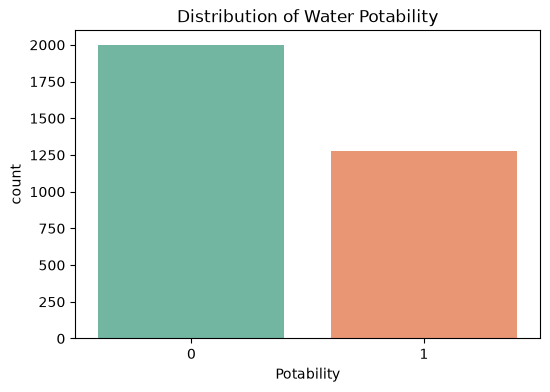

Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64


In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Potability',hue='Potability', data=df, palette='Set2', legend=False)
plt.title('Distribution of Water Potability')
plt.show()

print(df['Potability'].value_counts(normalize=True) * 100)
    

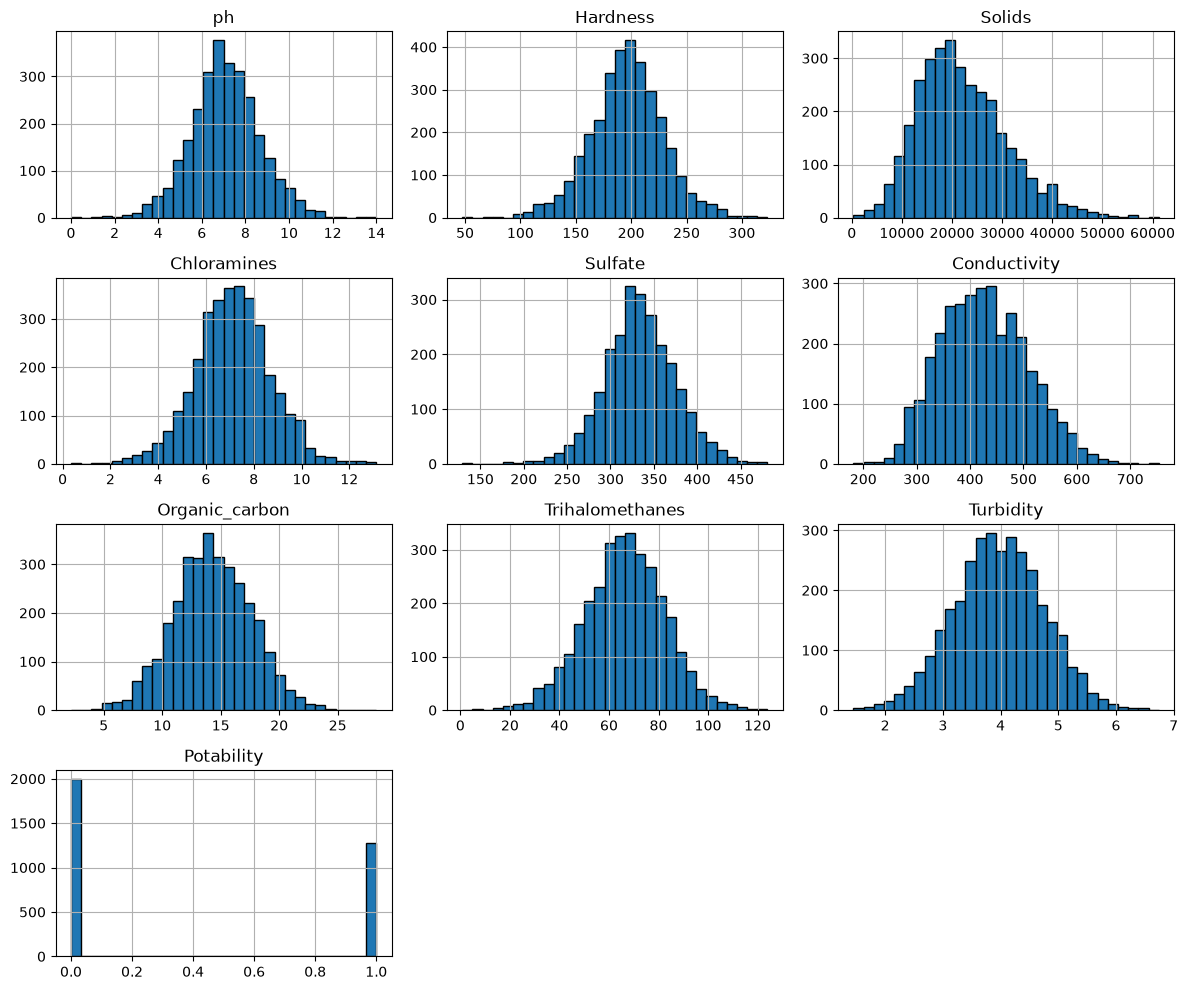

In [12]:

df.hist(bins=30, figsize=(12, 10), edgecolor='black')
plt.tight_layout()
plt.show()

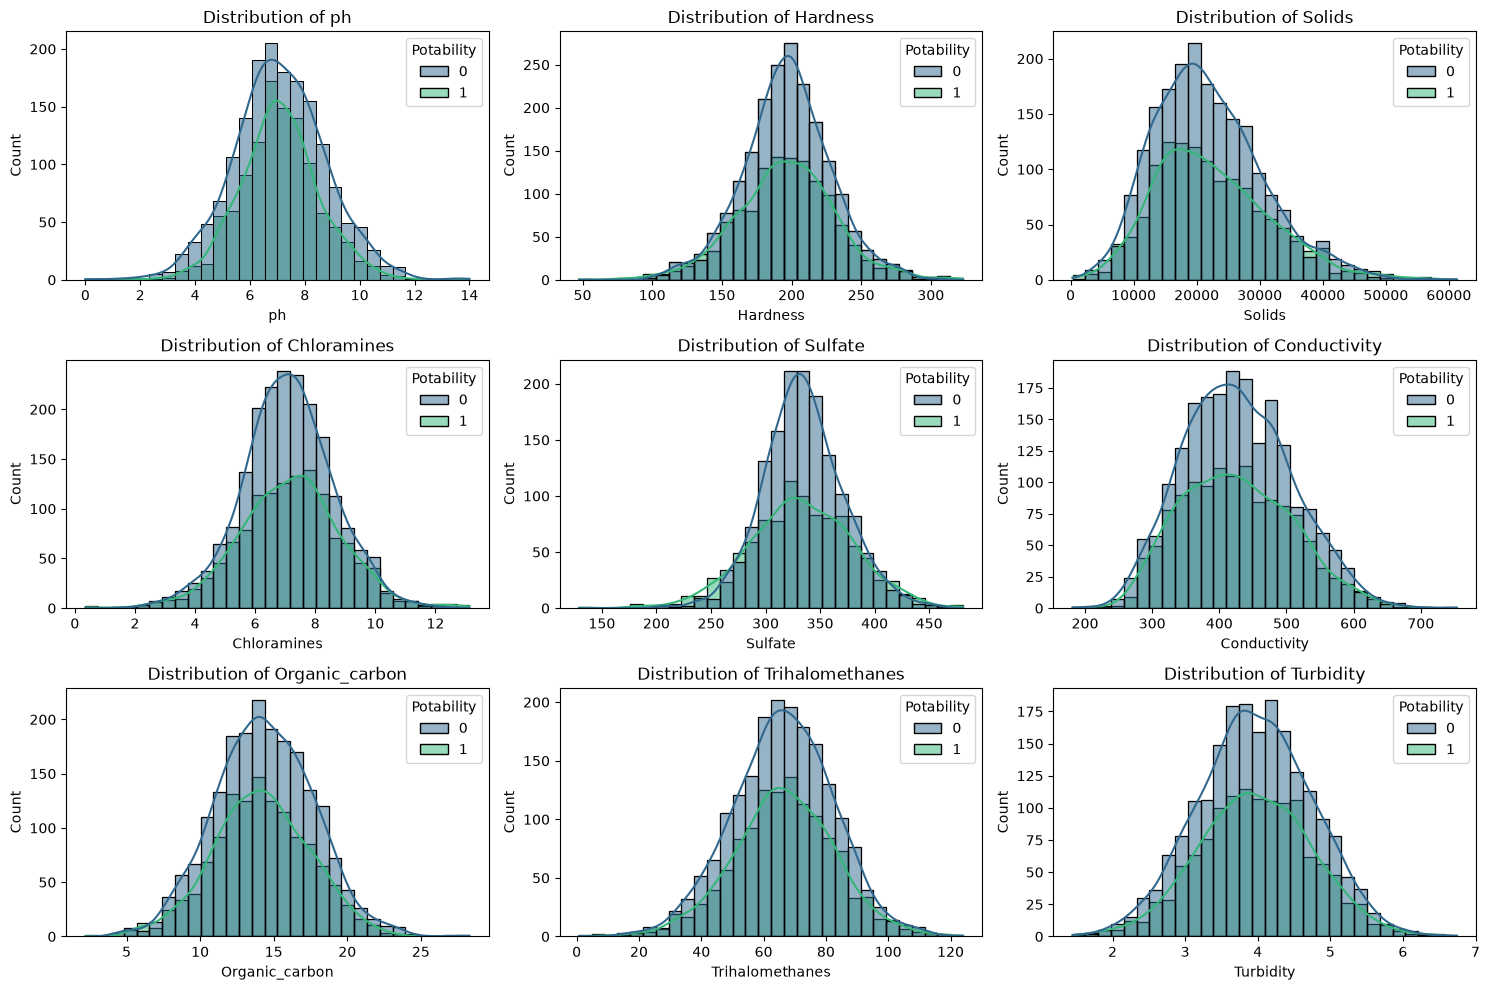

In [13]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(df.columns[:-1]): 
    plt.subplot(3, 3, i + 1)
    sns.histplot(data=df, x=col, hue='Potability', kde=True, bins=30, palette='viridis')
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
plt.show()

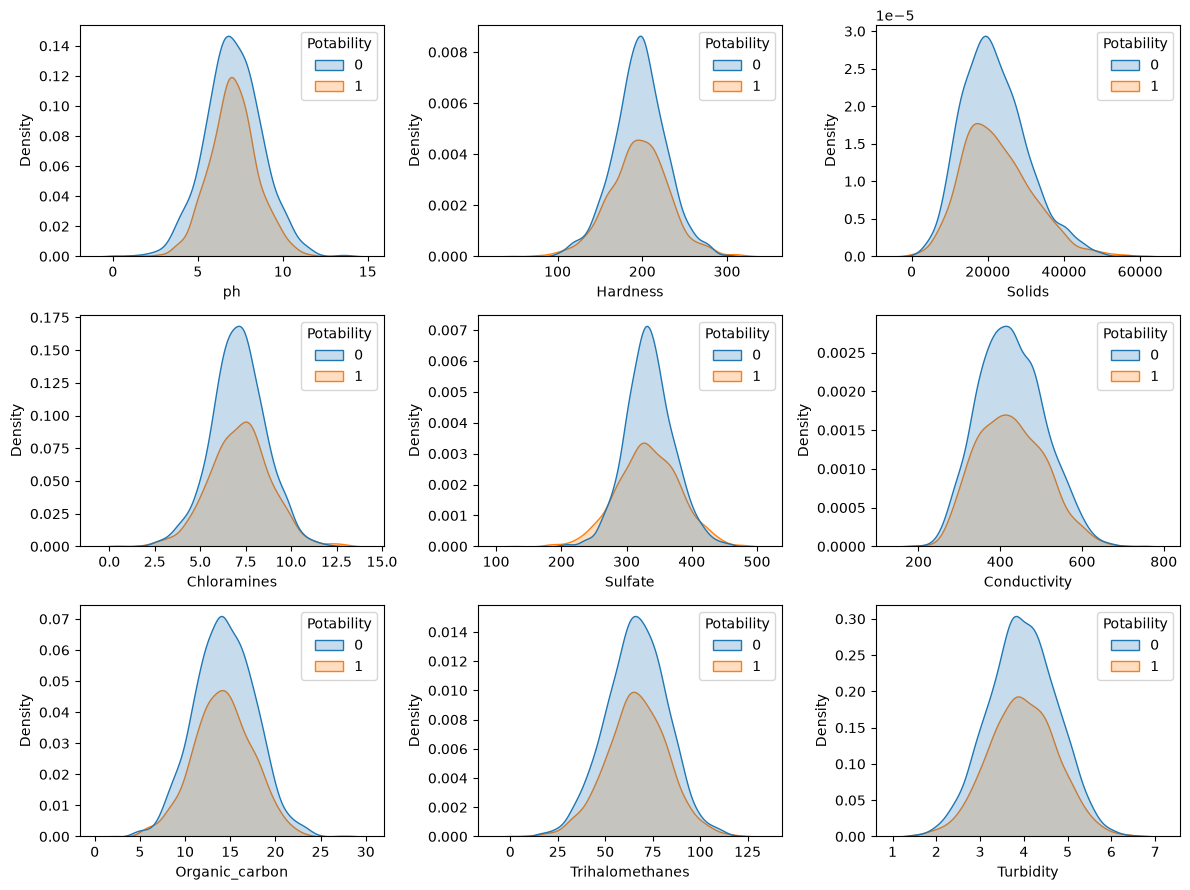

In [14]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

df = pd.read_csv('water_potability_2dec.csv')
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
[sns.kdeplot(df, x=c, hue='Potability', fill=True, ax=ax) for ax, c in zip(axes.flat, df.select_dtypes('float64'))]
plt.tight_layout()

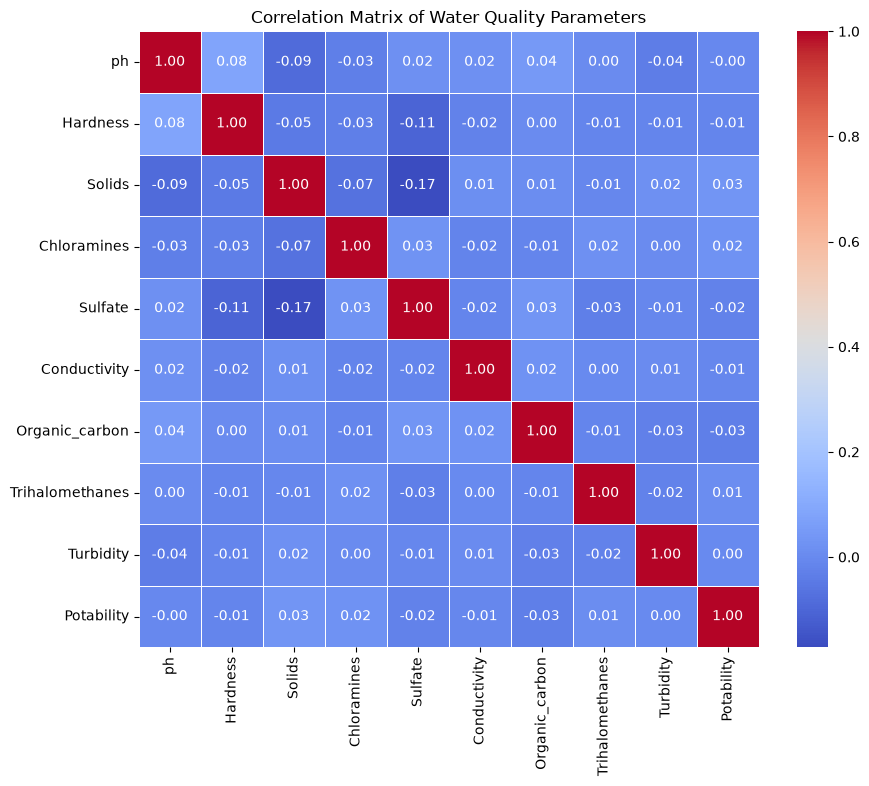

In [15]:

corr_matrix = df.corr()


plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Water Quality Parameters')
plt.show()

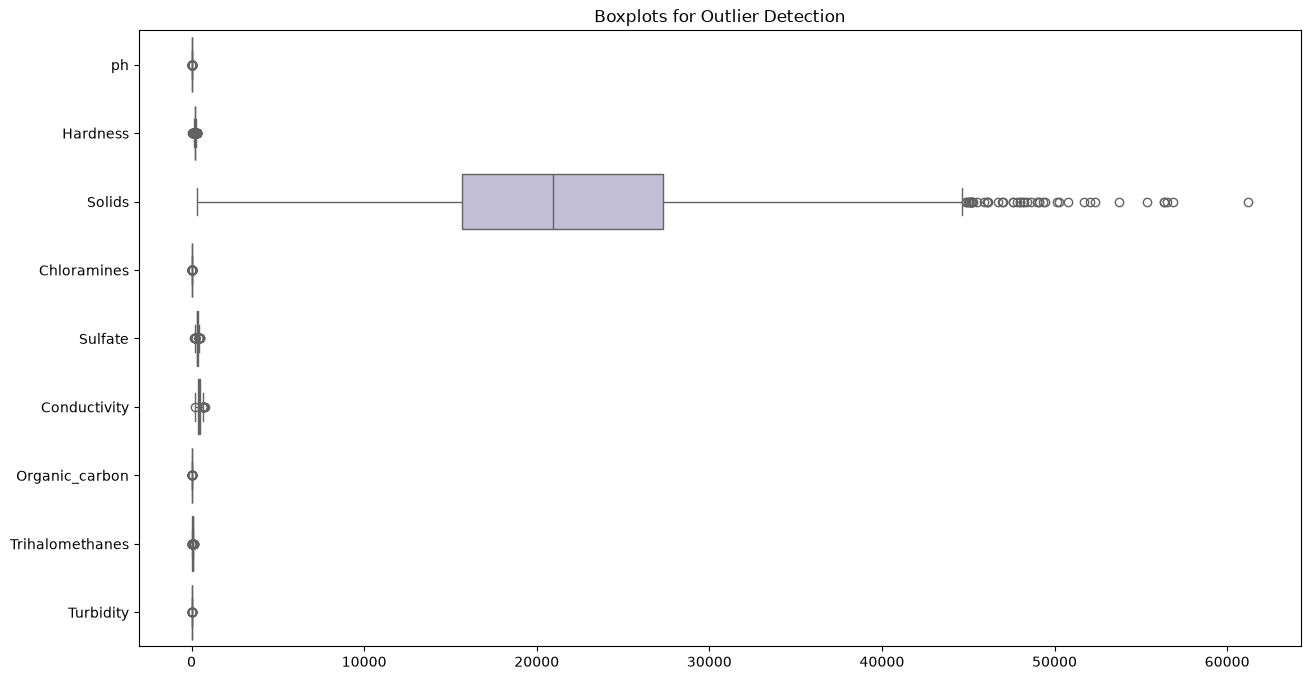

In [16]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df.drop(columns=['Potability']), orient='h', palette='Set3')
plt.title('Boxplots for Outlier Detection')
plt.show()

In [17]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.drop('Potability')

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [18]:
for col in numerical_cols:
    df[col] = np.where(df[col] < lower_bound[col], lower_bound[col], df[col])
    df[col] = np.where(df[col] > upper_bound[col], upper_bound[col], df[col])

In [19]:
for col in ['ph', 'Sulfate', 'Trihalomethanes']:
    df[col] = df[col].fillna(df.groupby('Potability')[col].transform('median'))

In [20]:
df.fillna(df.median(), inplace=True)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.035,204.89,20791.32000,7.30,368.52,564.31,10.38,86.99,2.96,0
1,3.720,129.42,18630.06000,6.64,333.39,592.89,15.18,56.33,4.50,0
2,8.100,224.24,19909.54000,9.28,333.39,418.61,16.87,66.42,3.06,0
3,8.320,214.37,22018.42000,8.06,356.89,363.27,18.44,100.34,4.63,0
4,9.090,181.10,17978.99000,6.55,310.14,398.41,11.56,32.00,4.08,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.670,193.68,44831.86875,7.17,359.95,526.42,13.89,66.69,4.44,1
3272,7.810,193.55,17329.80000,8.06,331.84,392.45,19.90,66.68,2.80,1
3273,9.420,175.76,33155.58000,7.35,331.84,432.04,11.04,69.85,3.30,1
3274,5.130,230.60,11983.87000,6.30,331.84,402.88,11.17,77.49,4.71,1


In [21]:


X = df.drop(columns=['Potability'])
y = df['Potability']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [22]:

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:

df['Hardness_Solids_Ratio'] = df['Hardness'] / (df['Solids'] + 1e-5)

df['Conductivity_Solids_Ratio'] = df['Conductivity'] / (df['Solids'] + 1e-5)

#
df['Disinfectant_Product'] = df['Chloramines'] * df['Trihalomethanes']

# 4. pH Balance Deviation Indicator
# Pure/ideal drinking water neutral pH is around 7. 
df['pH_Deviation_from_Neutral'] = np.abs(df['ph'] - 7.0)

print("New engineered features added successfully!")
print(df[['Hardness_Solids_Ratio', 'Conductivity_Solids_Ratio', 'Disinfectant_Product', 'pH_Deviation_from_Neutral']].head())

New engineered features added successfully!
   Hardness_Solids_Ratio  Conductivity_Solids_Ratio  Disinfectant_Product  \
0               0.009855                   0.027142              635.0270   
1               0.006947                   0.031824              374.0312   
2               0.011263                   0.021026              616.3776   
3               0.009736                   0.016498              808.7404   
4               0.010073                   0.022160              209.6000   

   pH_Deviation_from_Neutral  
0                      0.035  
1                      3.280  
2                      1.100  
3                      1.320  
4                      2.090  


In [24]:
f

print("--- Logistic Regression Baseline ---")
# Logistic regression requires scaled data because it relies on distance/coefficients
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, lr_preds))
print("ROC-AUC:", roc_auc_score(y_test, lr_probs))
print("\nClassification Report:\n", classification_report(y_test, lr_preds))


print("\n--- Decision Tree Baseline ---")
# Decision trees do not strictly require scaled data, but using X_train/X_test directly is fine
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

dt_preds = dt_model.predict(X_test)
dt_probs = dt_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, dt_preds))
print("ROC-AUC:", roc_auc_score(y_test, dt_probs))
print("\nClassification Report:\n", classification_report(y_test, dt_preds))
   

--- Logistic Regression Baseline ---
Accuracy: 0.6097560975609756
ROC-AUC: 0.55130859375

Classification Report:
               precision    recall  f1-score   support

           0       0.61      1.00      0.76       400
           1       0.00      0.00      0.00       256

    accuracy                           0.61       656
   macro avg       0.30      0.50      0.38       656
weighted avg       0.37      0.61      0.46       656


--- Decision Tree Baseline ---
Accuracy: 0.7423780487804879
ROC-AUC: 0.80880859375

Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.93      0.81       400
           1       0.80      0.45      0.58       256

    accuracy                           0.74       656
   macro avg       0.76      0.69      0.70       656
weighted avg       0.76      0.74      0.72       656



c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

In [25]:
!pip install xgb

ERROR: Could not find a version that satisfies the requirement xgb (from versions: none)
ERROR: No matching distribution found for xgb


In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

print("--- Random Forest (Balanced) ---")
rf_model = RandomForestClassifier(
    n_estimators=300, 
    max_depth=12, 
    class_weight='balanced',  # Automatically adjusts weights inversely proportional to class frequencies
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, rf_preds))
print("ROC-AUC:", roc_auc_score(y_test, rf_probs))
print("\nClassification Report:\n", classification_report(y_test, rf_preds))



--- Random Forest (Balanced) ---
Accuracy: 0.8033536585365854
ROC-AUC: 0.8804199218750001

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.88      0.85       400
           1       0.79      0.68      0.73       256

    accuracy                           0.80       656
   macro avg       0.80      0.78      0.79       656
weighted avg       0.80      0.80      0.80       656



In [27]:
print(type(rf_model))
print(rf_model)

<class 'sklearn.ensemble._forest.RandomForestClassifier'>
RandomForestClassifier(class_weight='balanced', max_depth=12, n_estimators=300,
                       n_jobs=-1, random_state=42)


In [28]:
import pickle 
pickle.dump(rf_model, open('rf_model.pkl', 'wb'))
pickle.dump(df, open('df.pkl', 'wb'))